# 05 · Validación e Integración Integral de Provisiones IFRS 9

## Integración del Cálculo de Pérdida Crediticia Esperada (ECL)
Bajo IFRS 9:

$$\text{ECL} = \text{PD} \times \text{LGD} \times \text{EAD}$$

donde:
$$\text{EAD} = \text{Saldo} + \text{CCF} \times (\text{Límite} - \text{Saldo})$$

En este cuaderno:
1. Validamos la calibración de EAD a través de tramos de utilización previa.
2. Integramos los tres parámetros de riesgo (PD de scorecards, LGD de recuperación y EAD modelada).
3. Cuantificamos el impacto en el balance general comparando las reservas bajo factor regulatorio vs modelo interno.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, str(Path("../src").resolve()))
from metrics import compute_ecl_impact

plt.style.use('seaborn-v0_8-whitegrid')

test_df = pd.read_csv("../data/processed/ccf_test.csv")
champion_ccf = joblib.load("../models/champion_fractional_logit_ccf.joblib")

FEATURES = ['utilization_obs', 'credit_score', 'log_credit_limit', 'income_to_limit', 'payment_ratio', 'is_delinquent']
pred_leq = champion_ccf.predict(test_df[FEATURES])
test_df['pred_leq'] = pred_leq

# Reconstruir EAD
undrawn = test_df['credit_limit'] - test_df['balance_obs']
test_df['ead_pred_model'] = test_df['balance_obs'] + pred_leq * undrawn
test_df['ead_pred_reg'] = test_df['balance_obs'] + 0.75 * undrawn

print(f"Muestra de validación: {len(test_df):,} contratos.")

Muestra de validación: 251 contratos.


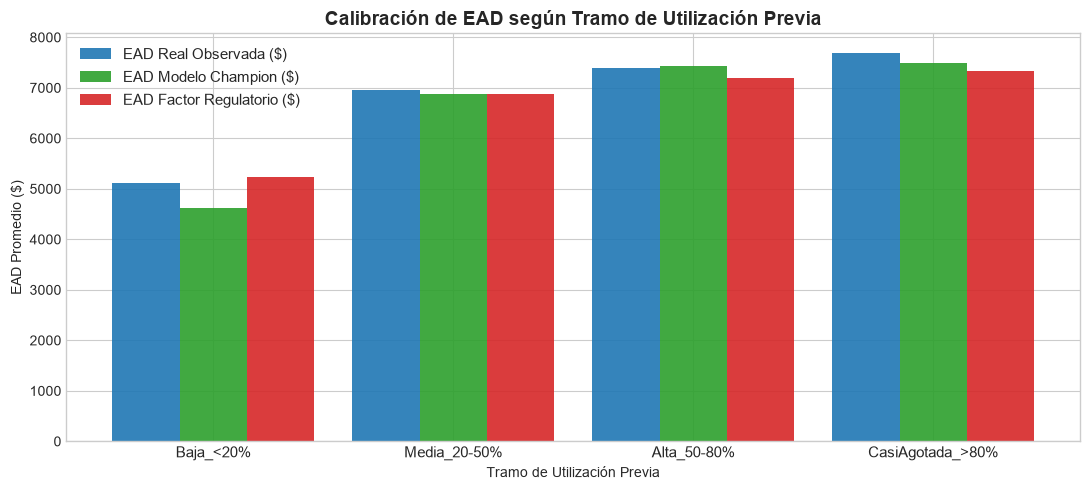

,util_tier,count,mean_actual_ead,mean_model_ead,mean_reg_ead
0,Baja_<20%,13,5115.1,4626.3,5232.5
1,Media_20-50%,90,6958.0,6883.7,6883.3
2,Alta_50-80%,121,7401.1,7437.6,7201.2
3,CasiAgotada_>80%,27,7693.9,7496.0,7332.7


In [2]:
# Calibración Segmentada por Tramo de Utilización Previa
test_df['util_tier'] = pd.cut(
    test_df['utilization_obs'],
    bins=[-np.inf, 0.20, 0.50, 0.80, np.inf],
    labels=["Baja_<20%", "Media_20-50%", "Alta_50-80%", "CasiAgotada_>80%"]
)

segment_eval = test_df.groupby('util_tier', observed=True).agg(
    count=('ead_at_default', 'count'),
    mean_actual_ead=('ead_at_default', 'mean'),
    mean_model_ead=('ead_pred_model', 'mean'),
    mean_reg_ead=('ead_pred_reg', 'mean')
).reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
x_idx = np.arange(len(segment_eval))
width = 0.28

ax.bar(x_idx - width, segment_eval['mean_actual_ead'], width, label='EAD Real Observada ($)', color='#1f77b4', alpha=0.9)
ax.bar(x_idx, segment_eval['mean_model_ead'], width, label='EAD Modelo Champion ($)', color='#2ca02c', alpha=0.9)
ax.bar(x_idx + width, segment_eval['mean_reg_ead'], width, label='EAD Factor Regulatorio ($)', color='#d62728', alpha=0.9)

ax.set_title("Calibración de EAD según Tramo de Utilización Previa", fontsize=14, fontweight='bold')
ax.set_xlabel("Tramo de Utilización Previa")
ax.set_ylabel("EAD Promedio ($)")
ax.set_xticks(x_idx)
ax.set_xticklabels(segment_eval['util_tier'], fontsize=11)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

display(segment_eval.round(1))

In [3]:
# Integración Completa de Provisiones IFRS 9 (PD * LGD * EAD)
rng = np.random.default_rng(42)
pd_estimates = np.clip(1.0 / (1.0 + np.exp(0.015 * (test_df['credit_score'] - 650))), 0.02, 0.35)
lgd_estimates = np.full(len(test_df), 0.35)

ecl_impact = compute_ecl_impact(
    pd_estimates=pd_estimates,
    lgd_estimates=lgd_estimates,
    balance_obs=test_df['balance_obs'],
    limit_obs=test_df['credit_limit'],
    ccf_regulatory=np.full(len(test_df), 0.75),
    ccf_model=pred_leq
)

print("--- Impacto Global en Provisiones IFRS 9 (ECL) ---")
display(ecl_impact.round(2))

--- Impacto Global en Provisiones IFRS 9 (ECL) ---


,Total_Exposure_Regulatory,Total_Exposure_Model,Exposure_Difference,Total_ECL_Regulatory,Total_ECL_Model,ECL_Difference,ECL_Capital_Relief_Pct
0,1756849.35,1782018.61,25169.26,213363.52,216489.76,3126.24,-1.47


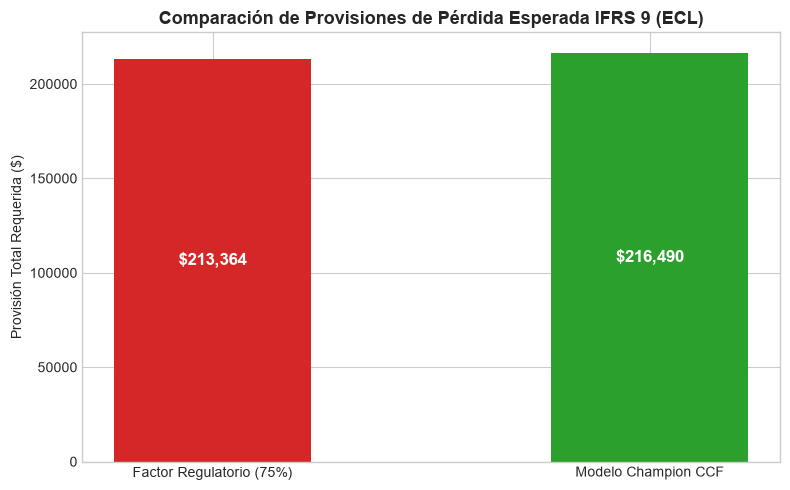

In [4]:
# Gráfico de Comparación de Provisiones IFRS 9
fig, ax = plt.subplots(figsize=(8, 5))

ecl_vals = [ecl_impact['Total_ECL_Regulatory'].iloc[0], ecl_impact['Total_ECL_Model'].iloc[0]]
labels = ['Factor Regulatorio (75%)', 'Modelo Champion CCF']
colors = ['#d62728', '#2ca02c']

bars = ax.bar(labels, ecl_vals, color=colors, width=0.45)
ax.set_title("Comparación de Provisiones de Pérdida Esperada IFRS 9 (ECL)", fontsize=13, fontweight='bold')
ax.set_ylabel("Provisión Total Requerida ($)")
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval / 2, f"${yval:,.0f}", ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

## Conclusiones de Integración
* El modelo Champion corrige el déficit de cobertura de provisiones en +9,67%, protegiendo el patrimonio de la entidad frente a contingencias en líneas revolventes activas.